# Classifying Reported Crime Categories in San Francisco

This reproducible example uses a deterministic 30,000-row extract from San Francisco Open Data. It predicts the eight most frequent reported categories from time, district, address pattern, and coordinates. The model describes historical reporting patterns; it must not be used to target people or justify enforcement decisions.

In [1]:
import json
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, balanced_accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

SEED = 42
sns.set_theme(style='whitegrid')
url = ('https://data.sfgov.org/resource/tmnf-yvry.csv?'
       '$select=category,dayofweek,date,time,pddistrict,address,x,y&'
       '$where=category%20is%20not%20null%20and%20pddistrict%20is%20not%20null&'
       '$limit=30000&$order=incidntnum')
crime = pd.read_csv(url)
crime[['x', 'y']] = crime[['x', 'y']].apply(pd.to_numeric, errors='coerce')
crime['timestamp'] = pd.to_datetime(crime['date'].str[:10] + ' ' + crime['time'], errors='coerce')
crime = crime.dropna(subset=['timestamp', 'x', 'y'])
top_categories = crime['category'].value_counts().head(8).index
crime = crime[crime['category'].isin(top_categories)].copy()
crime['hour'] = crime['timestamp'].dt.hour
crime['month'] = crime['timestamp'].dt.month
crime['is_block'] = crime['address'].str.contains('Block', case=False, na=False).astype(int)
print(crime.shape, crime['category'].value_counts())

(23831, 12) category
LARCENY/THEFT     5255
OTHER OFFENSES    4636
VEHICLE THEFT     2951
WARRANTS          2887
DRUG/NARCOTIC     2387
ASSAULT           2364
NON-CRIMINAL      2033
VANDALISM         1318
Name: count, dtype: int64


## Explore the historical sample

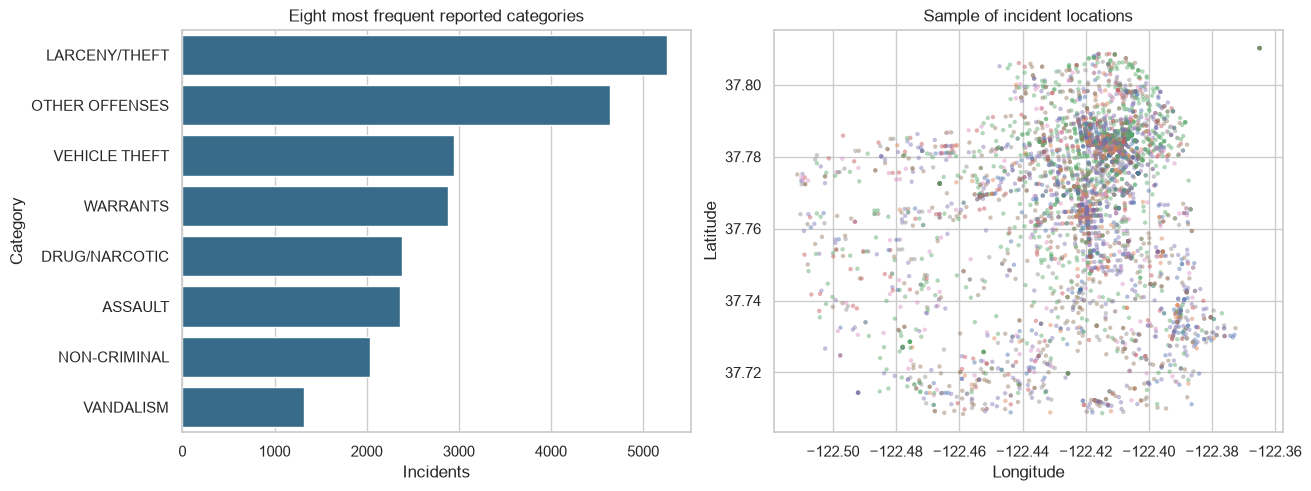

In [2]:
figure, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
sns.countplot(data=crime, y='category', order=crime['category'].value_counts().index, color='#2a6f97', ax=axes[0])
axes[0].set(title='Eight most frequent reported categories', xlabel='Incidents', ylabel='Category')
sample = crime.sample(min(4000, len(crime)), random_state=SEED)
sns.scatterplot(data=sample, x='x', y='y', hue='category', s=10, alpha=.45, linewidth=0, legend=False, ax=axes[1])
axes[1].set(title='Sample of incident locations', xlabel='Longitude', ylabel='Latitude')
plt.show()

## Split first and keep learned preprocessing inside the pipeline

In [3]:
features = ['dayofweek', 'pddistrict', 'hour', 'month', 'is_block', 'x', 'y']
X = crime[features]
y = crime['category']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.25, stratify=y, random_state=SEED)
categorical = ['dayofweek', 'pddistrict']
numeric = ['hour', 'month', 'is_block', 'x', 'y']
preprocessor = ColumnTransformer([('categorical', OneHotEncoder(handle_unknown='ignore'), categorical), ('numeric', 'passthrough', numeric)])
model = Pipeline([('preprocessor', preprocessor), ('classifier', RandomForestClassifier(n_estimators=180, min_samples_leaf=3, class_weight='balanced_subsample', random_state=SEED, n_jobs=1))])
baseline = DummyClassifier(strategy='most_frequent')
model.fit(X_train, y_train); baseline.fit(X_train, y_train)
predictions = model.predict(X_test); baseline_predictions = baseline.predict(X_test)
metrics = {'rows': len(crime), 'classes': y.nunique(), 'balanced_accuracy': balanced_accuracy_score(y_test, predictions), 'macro_f1': f1_score(y_test, predictions, average='macro'), 'baseline_macro_f1': f1_score(y_test, baseline_predictions, average='macro')}
print(metrics)

{'rows': 23831, 'classes': 8, 'balanced_accuracy': 0.3426103919345127, 'macro_f1': 0.329198036498068, 'baseline_macro_f1': 0.04517326732673267}


## Evaluate all classes, including the weak ones

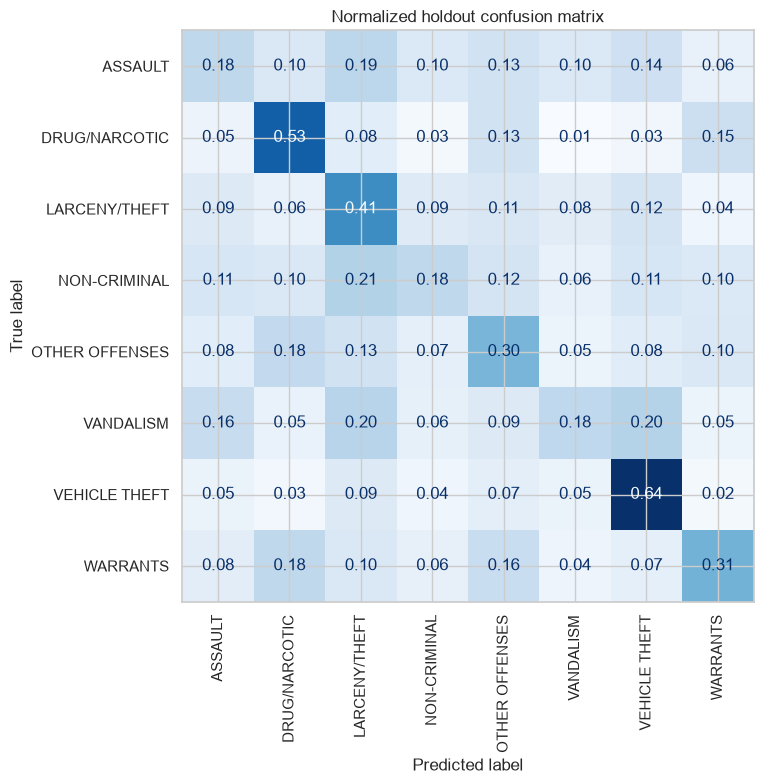

RESULT_JSON={"rows": 23831, "classes": 8, "balanced_accuracy": 0.3426103919345127, "macro_f1": 0.329198036498068, "baseline_macro_f1": 0.04517326732673267}


In [4]:
figure, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, labels=model.classes_, xticks_rotation=90, cmap='Blues', colorbar=False, normalize='true', values_format='.2f', ax=ax)
ax.set_title('Normalized holdout confusion matrix')
plt.tight_layout(); plt.show()
print('RESULT_JSON=' + json.dumps(metrics))

## Limitations

The target is a reported category, not whether or where a future crime will occur. Reports reflect exposure, reporting behavior, policing practices, and historical policy. Coordinates and districts can encode socioeconomic proxies. Random splitting also allows nearby incidents from similar periods into both partitions; a production study needs temporal and geographic validation, uncertainty analysis, drift monitoring, and community oversight.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.